# Notebook E14: Pembanding Rekonstruksi Sinyal Graf Bervariasi Waktu

**Proyek:** STMAC pada *cellular sheaf* untuk rekonstruksi irradiansi Arab Saudi
**Kaitan dengan naskah:** Bagian II (*Spatio-temporal gap filling*), Bagian V-F, Bagian VI-B (*Limitations*)

## Tujuan

Reviewer SUSTAIN 2026 mencatat bahwa naskah belum membandingkan STMAC dengan metode rekonstruksi spasio-temporal berbasis graf yang lebih baru. Pembanding di E9/E12 baru *low-rank completion* (2010) dan GRMF (2015). Pada notebook ini kita menjalankan tiga metode *time-varying graph signal recovery* (pemulihan sinyal graf bervariasi waktu) dari jurnal IEEE pada sepuluh *mask* (pola sel hilang) yang sama dengan E9J:

| Kode | Metode | Sumber |
|---|---|---|
| TVGSR | kehalusan graf pada selisih temporal | Qiu dkk., *IEEE J. Sel. Topics Signal Process.*, 11(6), 2017 |
| GraphTRSS | norma Sobolev $(L+\varepsilon I)^\beta$ pada selisih temporal | Giraldo dkk., *IEEE TSIPN*, 8, 2022, doi:10.1109/TSIPN.2022.3156886 |
| RTVGSR | Laplacian graf + variasi total temporal + kendala bola-$\varepsilon$ | Yamagata, Naganuma, Ono, *IEEE TSIPN*, 11, 2025, doi:10.1109/TSIPN.2025.3525978 |

Ketiganya bekerja pada sinyal mentah dengan peta restriksi identitas dan tidak memerlukan *training* (pelatihan), sehingga setara dengan STMAC dari sisi kebutuhan data. Kita juga menjalankan varian TVGSR dan GraphTRSS yang memakai prior klimatologi MDV yang sama dengan STMAC. Varian ini memisahkan dua sumber akurasi: prior klimatologi dan bentuk regularisasi graf.

## Protokol

Protokol mengikuti E12 bagian E9J tanpa perubahan:

1. Data: 11 stasiun NLR 1999, resolusi 5 menit, 101.805 *timestamp*.
2. *Mask*: 10% sel per stasiun hilang dalam blok kontigu, tujuh panjang blok (30 menit sampai 7 hari), *seed* 0 sampai 9 (`sj.build_block_mask`).
3. Skor: RMSE pada sel hilang pukul 08:00 sampai 16:55 waktu lokal, juga dipisah menurut sel cerah ($k_t > 0{,}85$) dan berawan ($k_t < 0{,}70$).
4. Bobot setiap metode dipilih dengan *block cross-validation* (validasi silang blok) yang sama dengan STMAC: *mask* dengan *seed* 101, 5% sel teramati disembunyikan dalam blok, skor dirata-rata atas tujuh panjang blok. Sel yang dievaluasi tidak pernah dipakai untuk memilih bobot.
5. Uji: Wilcoxon *signed-rank* berpasangan per panjang blok, koreksi Holm di dalam setiap keluarga uji.

Nilai STMAC ($r = 10^3$, $g = 3$, sheaf longitude), MDV, dan S0 diambil dari `E12_E9J_raw.csv`. Dua baris dihitung ulang di sini sebagai pemeriksaan.

## 1. Lingkungan dan data

Notebook ini berada di folder yang sama dengan E1 sampai E13 dan memerlukan modul `stmac_joint.py`, `stmac_rerun_utils.py`, `sky_tools.py`, serta modul baru `st_graph_recent.py`. Semua hasil disimpan di `results/` dengan awalan `E14_`. Setiap perulangan menyimpan hasil per baris, jadi notebook dapat dijalankan ulang dari titik terakhir bila terhenti.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse, stats
from scipy.sparse.linalg import spsolve

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13.5,
    "xtick.labelsize": 12.5, "ytick.labelsize": 12.5, "legend.fontsize": 12,
    "figure.dpi": 110, "savefig.dpi": 400, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

HERE = Path.cwd().resolve()
for p in (HERE, HERE.parent, HERE / "notebooks"):
    if (p / "stmac_joint.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import stmac_joint as sj
import stmac_rerun_utils as ru
import sky_tools as sk
import st_graph_recent as gr

DATA = ru.locate("data", "multistation_1999_cleaned.parquet")
ROOT = DATA.parent
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

N_SEEDS_E9 = 10            # sepuluh mask bersama E9/E9J
SEL_SEED = 101             # mask untuk pemilihan bobot (sama dengan STMAC)
CV_HIDE_FRAC = 0.05
KT_CLEAR, KT_CLOUDY = 0.85, 0.70
MDV_HW = 15
R_AN, G_AN = 1000.0, 3.0   # bobot STMAC terpilih di E12
BLOCKS = sj.BLOCK_SPECS
LABEL = dict(BLOCKS)

multi = pd.read_parquet(DATA / "multistation_1999_cleaned.parquet")
STATIONS = json.load(open(DATA / "stations.json"))
CODES = list(STATIONS)
multi = multi[CODES]
LAT = np.array([STATIONS[c]["lat"] for c in CODES], float)
LON = np.array([STATIONS[c]["lon"] for c in CODES], float)
U_ALL = multi.to_numpy().T.astype(float)
N, T = U_ALL.shape
IDX = multi.index
DELTA = (LON - LON.mean()) / 15 * 60 / 5
L_G = np.load(DATA / "graph_L.npy")
L_TIME = sj.build_temporal_smoothness(T)
DAYTIME = (IDX.hour.values >= 8) & (IDX.hour.values <= 16)


def idn(x, nd=1):
    # angka dengan koma desimal dan titik ribuan
    s = f"{x:,.{nd}f}"
    return s.replace(",", "_").replace(".", ",").replace("_", ".")


def load_csv(name):
    p = RES / name
    return pd.read_csv(p) if p.exists() else None


print(f"DATA    : {DATA}")
print(f"RESULTS : {RES}")
print(f"{N} stasiun | {T:,} timestamp | sel siang {DAYTIME.sum():,} | puncak {U_ALL.max():.1f} W/m2")
print(f"lambda_max(L_G) = {np.linalg.eigvalsh(L_G).max():.3f} | derajat rata-rata {np.diag(L_G).mean():.3f}")

DATA    : /Users/user/Desktop/Proyek lomba paper/Project KFUPM/Final 5/stmac-demo 2/notebooks/data
RESULTS : /Users/user/Desktop/Proyek lomba paper/Project KFUPM/Final 5/stmac-demo 2/notebooks/results
11 stasiun | 101,805 timestamp | sel siang 38,730 | puncak 1961.5 W/m2
lambda_max(L_G) = 2.685 | derajat rata-rata 1.280


## 2. Rumusan dan pemeriksaan solver

Notasi: $Y$ matriks pengamatan $N \times T$, $J$ *mask* (1 = teramati), $D_h$ operator selisih temporal orde satu, $L$ Laplacian graf kombinatorial yang sama dengan STMAC ($k = 3$, kernel Gauss $\sigma = 300$ km).

**TVGSR** (Qiu dkk., 2017):
$$\min_X \tfrac12\|J\circ(X-Y)\|_F^2 + \tfrac{\nu}{2}\,\mathrm{tr}\big((XD_h)^\top L\,(XD_h)\big)$$

**GraphTRSS** (Giraldo dkk., 2022, Pers. 17):
$$\min_X \tfrac12\|J\circ(X-Y)\|_F^2 + \tfrac{\nu}{2}\,\mathrm{tr}\big((XD_h)^\top (L+\varepsilon I)^\beta\,(XD_h)\big)$$
TVGSR adalah kasus $\varepsilon = 0$, $\beta = 1$.

**RTVGSR** (Yamagata dkk., 2025, Pers. 13). Jaringan kita statis, jadi $L_k = L$ untuk setiap slot waktu:
$$\min_X \sum_k P(X)_k^\top L\,P(X)_k + \lambda\,\|D(X)\|_1 \quad \text{s.t.}\quad \|Y-\Phi(X)\|_F \le \varepsilon_b$$
dengan $P(X) = X$ (metode L/M naskah aslinya) atau $P(X) = D(X)$ (metode H/I). Pencilan tidak kita suntikkan, sehingga aturan $\eta = P_s\,np/2$ dari naskah aslinya memberi $\eta = 0$ dan $S = 0$. Jari-jari bola mengikuti aturan aslinya, $\varepsilon_b = 0{,}9\,\sigma\sqrt{n_{\mathrm{obs}}}$, dengan $\sigma$ ditaksir dari MAD selisih orde dua sel teramati.

**Catatan solver.** TVGSR dan GraphTRSS adalah kuadrat konveks dengan minimizer tunggal. Naskah aslinya memakai *conjugate gradient*; kita menyelesaikan sistem normalnya langsung. Dengan vektorisasi kolom, matriksnya berbentuk pita selebar $2N-1$, sehingga dekomposisi Cholesky pita memberi solusi eksak. RTVGSR diselesaikan dengan ADMM yang memakai faktorisasi pita yang sama. Naskah aslinya memakai *primal-dual splitting* (PDS); kedua algoritma menuju optimum yang sama, dan sel di bawah memeriksa hal itu. PDS pada varian $P(X)=D(X)$ memerlukan puluhan ribu iterasi pada data setahun, sedangkan ADMM berhenti dalam puluhan iterasi.

Sel berikut memeriksa tiga hal pada masalah kecil (4 stasiun, 400 sampel): solver pita terhadap *sparse direct solver*, norma gradien di titik solusi, dan kesamaan ADMM dengan PDS.

In [2]:
rng = np.random.default_rng(0)
idx_s = [0, 2, 4, 5]
W_s = np.load(DATA / "graph_W.npy")[np.ix_(idx_s, idx_s)]
L_s = np.diag(W_s.sum(1)) - W_s
Ns, Ts = 4, 400
Y_s = np.abs(np.sin(np.linspace(0, 14, Ts)))[None] * 800 + rng.normal(0, 20, (Ns, Ts))
M_s, _ = sj.build_block_mask(Ns, Ts, 40, 0.2, seed=1)
Dh = sparse.diags([-np.ones(Ts - 1), np.ones(Ts - 1)], [0, -1], shape=(Ts, Ts - 1))

checks = []
for nu, eps, beta in [(5.0, 0.0, 1.0), (5.0, 0.1, 1.5), (50.0, 0.3, 2.0)]:
    X = gr.solve_sobolev_tv(Y_s, M_s, L_s, nu, eps, beta)
    S = gr.sobolev_operator(L_s, eps, beta)
    A = sparse.diags(M_s.T.ravel().astype(float)) + nu * sparse.kron(Dh @ Dh.T, sparse.csr_matrix(S))
    Xr = spsolve(A.tocsc(), np.where(M_s, Y_s, 0).T.ravel()).reshape(Ts, Ns).T
    G = np.where(M_s, X - Y_s, 0) + nu * (S @ (np.diff(X, axis=1) @ Dh.T.toarray()))
    tag = "TVGSR" if eps == 0 else f"GraphTRSS eps={eps}, beta={beta}"
    checks.append((f"{tag}: selisih maks vs sparse direct (W/m2)", float(np.abs(X - Xr).max())))
    checks.append((f"{tag}: norma gradien maks di solusi", float(np.abs(G).max())))
for vertex in ["X", "DX"]:
    Xp, ip = gr.rtvgsr_pds(Y_s, M_s, L_s, 0.05, 0.5, "l1", vertex, max_iter=400000, tol=1e-11,
                           min_iter=10, return_info=True)
    Xa, ia = gr.rtvgsr_admm(Y_s, M_s, L_s, 0.05, 0.5, "l1", vertex, rho=1.0, max_iter=20000,
                            tol=1e-9, return_info=True)
    checks.append((f"RTVGSR P={vertex}: selisih maks ADMM vs PDS (W/m2)", float(np.abs(Xp - Xa).max())))
    checks.append((f"RTVGSR P={vertex}: iterasi PDS", float(ip["iters"])))
    checks.append((f"RTVGSR P={vertex}: iterasi ADMM", float(ia["iters"])))
CHECKS = pd.DataFrame(checks, columns=["pemeriksaan", "nilai"])
ru.atomic_csv(CHECKS, RES / "E14_solver_checks.csv")
print(CHECKS.to_string(index=False, float_format=lambda v: f"{v:.3e}"))

                                                      pemeriksaan     nilai
                      TVGSR: selisih maks vs sparse direct (W/m2) 1.138e-05
                              TVGSR: norma gradien maks di solusi 8.353e-08
GraphTRSS eps=0.1, beta=1.5: selisih maks vs sparse direct (W/m2) 8.563e-06
        GraphTRSS eps=0.1, beta=1.5: norma gradien maks di solusi 8.292e-08
GraphTRSS eps=0.3, beta=2.0: selisih maks vs sparse direct (W/m2) 8.420e-07
        GraphTRSS eps=0.3, beta=2.0: norma gradien maks di solusi 8.066e-08
                      RTVGSR P=X: selisih maks ADMM vs PDS (W/m2) 1.628e-05
                                          RTVGSR P=X: iterasi PDS 1.533e+03
                                         RTVGSR P=X: iterasi ADMM 6.100e+02
                     RTVGSR P=DX: selisih maks ADMM vs PDS (W/m2) 5.829e-05
                                         RTVGSR P=DX: iterasi PDS 3.009e+04
                                        RTVGSR P=DX: iterasi ADMM 1.970e+02


Sel berikut membaca tabel pemeriksaan di atas dan menuliskan kesimpulannya. Ambang lolos: selisih solver pita terhadap *sparse direct solver* di bawah $10^{-3}$ W/m$^2$, dan selisih ADMM terhadap PDS di bawah $10^{-2}$ W/m$^2$.

In [3]:
c = dict(zip(CHECKS.pemeriksaan, CHECKS.nilai))
sel = [v for k, v in c.items() if "sparse direct" in k]
grd = [v for k, v in c.items() if "gradien" in k]
adm = [v for k, v in c.items() if "ADMM vs PDS" in k]
print("INTERPRETASI PEMERIKSAAN SOLVER")
print("=" * 88)
print(f"- Solver pita TVGSR/GraphTRSS berbeda paling banyak {max(sel):.1e} W/m2 dari sparse direct "
      f"solver pada tiga konfigurasi; norma gradien di titik solusi paling besar {max(grd):.1e}.")
print(f"- ADMM dan PDS pada rumusan Yamagata dkk. berbeda paling banyak {max(adm):.1e} W/m2, "
      "jadi keduanya mencapai optimum yang sama.")
print(f"- Untuk P(X) = D(X), PDS memerlukan {idn(c['RTVGSR P=DX: iterasi PDS'], 0)} iterasi dan ADMM "
      f"{idn(c['RTVGSR P=DX: iterasi ADMM'], 0)} iterasi pada masalah kecil ini.")
ok = max(sel) < 1e-3 and max(adm) < 1e-2
print("- Kesimpulan: implementasi " + ("lolos" if ok else "BELUM lolos") + " pemeriksaan kebenaran.")

INTERPRETASI PEMERIKSAAN SOLVER
- Solver pita TVGSR/GraphTRSS berbeda paling banyak 1.1e-05 W/m2 dari sparse direct solver pada tiga konfigurasi; norma gradien di titik solusi paling besar 8.4e-08.
- ADMM dan PDS pada rumusan Yamagata dkk. berbeda paling banyak 5.8e-05 W/m2, jadi keduanya mencapai optimum yang sama.
- Untuk P(X) = D(X), PDS memerlukan 30.088 iterasi dan ADMM 197 iterasi pada masalah kecil ini.
- Kesimpulan: implementasi lolos pemeriksaan kebenaran.


## 3. Pemilihan bobot dengan validasi silang blok

Setiap metode mendapat perlakuan yang sama dengan STMAC. Untuk setiap panjang blok, kita membuat *mask* dengan *seed* 101, menyembunyikan tambahan 5% sel teramati dalam blok sepanjang itu, menjalankan metode pada sel yang tersisa, lalu menghitung RMSE pada sel siang yang disembunyikan. Konfigurasi dengan rata-rata RMSE terkecil atas tujuh panjang blok dipakai pada evaluasi.

Kisi bobot:

- TVGSR dan TVGSR + MDV: $\nu \in \{0{,}3;\ 1;\ 3;\ 10;\ 30;\ 100;\ 300\}$.
- GraphTRSS dan GraphTRSS + MDV: $\nu \in \{1, 10, 100\}$, $\varepsilon \in \{0{,}01;\ 0{,}1;\ 1\}$, $\beta \in \{1;\ 1{,}5;\ 2\}$. Giraldo dkk. melaporkan $\beta$ 1,5 sampai 2 lebih baik pada data lingkungan.
- RTVGSR: $P(X) \in \{X, D(X)\}$, $\lambda \in \{0{,}001;\ 0{,}003;\ 0{,}01;\ 0{,}03;\ 0{,}1\}$ pada skala kW/m$^2$. Varian $D(X)$ dimulai dari solusi TVGSR ($\nu = 10$) dan varian $X$ dari interpolasi spasial; titik awal hanya mempercepat iterasi.
- TVGSR + MDV, waktu surya: varian eksploratif yang menjalankan TVGSR + MDV setelah stasiun digeser ke waktu surya lokal dengan pergeseran sheaf longitude STMAC, seperti E9B untuk *low-rank* dan GRMF.

Bagian ini memerlukan sekitar 15 sampai 20 menit pada CPU laptop.

In [4]:
NU_GRID = [0.3, 1.0, 3.0, 10.0, 30.0, 100.0, 300.0]
TRSS_GRID = [(nu, e, b) for nu in (1.0, 10.0, 100.0) for e in (0.01, 0.1, 1.0) for b in (1.0, 1.5, 2.0)]
RT_GRID = [(v, lam) for v in ("X", "DX") for lam in (0.001, 0.003, 0.01, 0.03, 0.1)]
ADMM_KW = dict(rho=3.0, max_iter=400, tol=1e-4)


def eps_ball_rule(U, mask):
    # aturan Yamagata dkk.: 0,9 * sigma * sqrt(jumlah sel teramati), skala kW/m2
    return 0.9 * gr.noise_sigma_mad(U, mask) / 1000.0 * np.sqrt(mask.sum())


def tvgsr_lst(U, mask, nu, C):
    # TVGSR pada anomali terhadap MDV di koordinat waktu surya (pergeseran sheaf longitude)
    Z, Ms = sj.to_solar_frame(np.where(mask, U - C, 0.0), mask, DELTA)
    return sj.from_solar_frame(gr.tvgsr(Z, Ms, L_G, nu), DELTA) + C


def run_method(key, cfg, U, mask, C):
    if key == "tvgsr":
        return gr.tvgsr(U, mask, L_G, cfg["nu"])
    if key == "tvgsr_mdv":
        return gr.tvgsr(U, mask, L_G, cfg["nu"], prior=C)
    if key == "graphtrss":
        return gr.graphtrss(U, mask, L_G, cfg["nu"], cfg["eps"], cfg["beta"])
    if key == "graphtrss_mdv":
        return gr.graphtrss(U, mask, L_G, cfg["nu"], cfg["eps"], cfg["beta"], prior=C)
    if key == "rtvgsr":
        X0 = gr.tvgsr(U, mask, L_G, 10.0) if cfg["vertex"] == "DX" else None
        return gr.rtvgsr_admm(U, mask, L_G, cfg["lam"], eps_ball_rule(U, mask), "l1", cfg["vertex"],
                              X0=X0, **ADMM_KW)
    if key == "tvgsr_mdv_lst":
        return tvgsr_lst(U, mask, cfg["nu"], C)
    raise KeyError(key)


GRIDS = {
    "tvgsr": [dict(nu=v) for v in NU_GRID],
    "tvgsr_mdv": [dict(nu=v) for v in NU_GRID],
    "graphtrss": [dict(nu=a, eps=b, beta=c) for a, b, c in TRSS_GRID],
    "graphtrss_mdv": [dict(nu=a, eps=b, beta=c) for a, b, c in TRSS_GRID],
    "rtvgsr": [dict(vertex=a, lam=b) for a, b in RT_GRID],
    "tvgsr_mdv_lst": [dict(nu=v) for v in NU_GRID],
}
NAMES = {"tvgsr": "TVGSR", "tvgsr_mdv": "TVGSR + MDV", "graphtrss": "GraphTRSS",
         "graphtrss_mdv": "GraphTRSS + MDV", "rtvgsr": "RTVGSR",
         "tvgsr_mdv_lst": "TVGSR + MDV, waktu surya",
         "anomaly": "STMAC", "climatology": "MDV", "joint_longitude": "STMAC tanpa prior (S0)"}

CV_OUT = RES / "E14_cv.csv"
rows = pd.read_csv(CV_OUT).to_dict("records") if CV_OUT.exists() else []
done = {(r["method"], r["cfg"], int(r["block_len"])) for r in rows}
t_start = time.time()
for bl, lab in BLOCKS:
    mask, _ = sj.build_block_mask(N, T, bl, 0.10, seed=SEL_SEED)
    fit_mask, hidden = sj.block_cv_mask(mask, bl, CV_HIDE_FRAC, seed=SEL_SEED + 7919)
    score = hidden & DAYTIME[None, :]
    C_fit = ru.mdv_field(U_ALL, fit_mask, IDX, MDV_HW)
    for key, grid in GRIDS.items():
        for cfg in grid:
            cid = json.dumps(cfg, sort_keys=True)
            if (key, cid, bl) in done:
                continue
            t0 = time.time()
            U_r = run_method(key, cfg, U_ALL, fit_mask, C_fit)
            rows.append({"method": key, "cfg": cid, "block_len": bl, "block_label": lab,
                         "cv_rmse": sj.rmse(U_ALL, U_r, score), "sec": time.time() - t0})
        ru.atomic_csv(pd.DataFrame(rows), CV_OUT)
    print(f"{lab:>7s} selesai | {(time.time() - t_start) / 60:.1f} menit", flush=True)
CV = pd.DataFrame(rows)
print(f"{len(CV)} baris validasi silang")

 30 min selesai | 4.8 menit
    2 h selesai | 10.5 menit
    6 h selesai | 16.3 menit
   12 h selesai | 21.7 menit
  1 day selesai | 27.9 menit
  3 day selesai | 31.8 menit
  7 day selesai | 35.8 menit
595 baris validasi silang


    2 h selesai | 0.0 menit


    6 h selesai | 0.0 menit


   12 h selesai | 0.0 menit


  1 day selesai | 0.0 menit


  3 day selesai | 0.0 menit


  7 day selesai | 0.0 menit


595 baris validasi silang


Untuk setiap metode, kita merata-ratakan RMSE validasi silang atas tujuh panjang blok, memilih konfigurasi dengan rata-rata terkecil, lalu menyimpannya ke `E14_selected_configs.csv`. Sebagai pembanding, tabel juga memuat skor validasi silang STMAC ($r = 10^3$, $g = 3$) dan MDV dari `E12_anomaly_cv.csv`, yang dihitung pada *mask* validasi yang sama.

In [5]:
pooled = CV.groupby(["method", "cfg"]).cv_rmse.mean().reset_index()
best = pooled.loc[pooled.groupby("method").cv_rmse.idxmin()].set_index("method")
SEL = {k: json.loads(best.loc[k, "cfg"]) for k in GRIDS}
ru.atomic_csv(best.reset_index(), RES / "E14_selected_configs.csv")

an_cv = load_csv("E12_anomaly_cv.csv")
stmac_cv = None
if an_cv is not None:
    a = an_cv[(an_cv.variant == "anomaly") & (an_cv.ratio == R_AN) & (an_cv.ridge == G_AN)]
    stmac_cv = a.set_index("block_label").cv_rmse
    clim_cv = an_cv[an_cv.variant == "climatology"].set_index("block_label").cv_rmse

tab = {}
for k in GRIDS:
    g = CV[(CV.method == k) & (CV.cfg == best.loc[k, "cfg"])].set_index("block_label").cv_rmse
    tab[NAMES[k]] = g
if stmac_cv is not None:
    tab["STMAC (E12)"] = stmac_cv
    tab["MDV (E12)"] = clim_cv
TAB_CV = pd.DataFrame(tab).loc[[l for _, l in BLOCKS]]
TAB_CV.loc["rata-rata"] = TAB_CV.mean()
print("Konfigurasi terpilih (rata-rata RMSE validasi silang atas tujuh panjang blok)")
for k in GRIDS:
    print(f"  {NAMES[k]:<26s} {best.loc[k, 'cfg']:<44s} {best.loc[k, 'cv_rmse']:7.2f} W/m2")
print("\nRMSE validasi silang per panjang blok (W/m2)")
print(TAB_CV.to_string(float_format=lambda v: f"{v:7.1f}"))

Konfigurasi terpilih (rata-rata RMSE validasi silang atas tujuh panjang blok)
  TVGSR                      {"nu": 10.0}                                  149.94 W/m2
  TVGSR + MDV                {"nu": 10.0}                                  142.78 W/m2
  GraphTRSS                  {"beta": 1.0, "eps": 0.01, "nu": 10.0}        149.42 W/m2
  GraphTRSS + MDV            {"beta": 1.0, "eps": 1.0, "nu": 1.0}          130.37 W/m2
  RTVGSR                     {"lam": 0.001, "vertex": "DX"}                155.22 W/m2
  TVGSR + MDV, waktu surya   {"nu": 10.0}                                  142.71 W/m2

RMSE validasi silang per panjang blok (W/m2)
              TVGSR  TVGSR + MDV  GraphTRSS  GraphTRSS + MDV  RTVGSR  TVGSR + MDV, waktu surya  STMAC (E12)  MDV (E12)
block_label                                                                                                           
30 min         74.4         76.4       73.3             67.6    78.4                      76.7         90.6      166

Interpretasi otomatis pemilihan bobot: urutan metode menurut RMSE validasi silang, konfigurasi yang jatuh di tepi kisi, dan panjang blok di mana pembanding sudah lebih rendah dari STMAC sebelum evaluasi.

In [6]:
print("INTERPRETASI PEMILIHAN BOBOT")
print("=" * 88)
m = TAB_CV.loc["rata-rata"]
order = m.sort_values()
print("- Urutan rata-rata RMSE validasi silang: " +
      "; ".join(f"{k} {idn(v)}" for k, v in order.items()) + " W/m2.")
tr = SEL["graphtrss"]
print(f"- GraphTRSS memilih nu = {idn(tr['nu'], 0)}, eps = {idn(tr['eps'], 2)}, beta = {idn(tr['beta'], 1)}"
      + (" (dekat dengan TVGSR)." if tr["beta"] == 1.0 and tr["eps"] <= 0.01 else "."))
rt = SEL["rtvgsr"]
print(f"- RTVGSR memilih P(X) = {'D(X)' if rt['vertex'] == 'DX' else 'X'} dengan lambda = {rt['lam']}.")
edge = []
for k in GRIDS:
    for par, val in SEL[k].items():
        vals = sorted({cfg[par] for cfg in GRIDS[k]}, key=str)
        if isinstance(val, (int, float)) and len(vals) > 1:
            nums = sorted(v for v in vals)
            if val in (nums[0], nums[-1]):
                edge.append(f"{NAMES[k]} ({par} = {val})")
if edge:
    print("- Konfigurasi di tepi kisi: " + "; ".join(edge) + ". Optimum metode itu bisa berada di luar "
          "kisi; memperluas kisi hanya dapat menurunkan RMSE validasi silangnya, jadi hasil di bawah tidak "
          "memberi keuntungan kepada pembanding.")
if "STMAC (E12)" in TAB_CV:
    s = TAB_CV["STMAC (E12)"].iloc[:-1]
    for k in ["TVGSR", "TVGSR + MDV", "GraphTRSS + MDV"]:
        d = TAB_CV[k].iloc[:-1] - s
        win = [l for l, v in d.items() if v < 0]
        print(f"- Pada validasi silang, {k} lebih rendah dari STMAC di {len(win)} dari 7 panjang blok"
              + (f" ({', '.join(win)})." if win else "."))

INTERPRETASI PEMILIHAN BOBOT
- Urutan rata-rata RMSE validasi silang: GraphTRSS + MDV 130,4; TVGSR + MDV, waktu surya 142,7; TVGSR + MDV 142,8; STMAC (E12) 145,8; GraphTRSS 149,4; TVGSR 149,9; RTVGSR 155,2; MDV (E12) 163,5 W/m2.
- GraphTRSS memilih nu = 10, eps = 0,01, beta = 1,0 (dekat dengan TVGSR).
- RTVGSR memilih P(X) = D(X) dengan lambda = 0.001.
- Konfigurasi di tepi kisi: GraphTRSS (beta = 1.0); GraphTRSS (eps = 0.01); GraphTRSS + MDV (beta = 1.0); GraphTRSS + MDV (eps = 1.0); GraphTRSS + MDV (nu = 1.0); RTVGSR (lam = 0.001). Optimum metode itu bisa berada di luar kisi; memperluas kisi hanya dapat menurunkan RMSE validasi silangnya, jadi hasil di bawah tidak memberi keuntungan kepada pembanding.
- Pada validasi silang, TVGSR lebih rendah dari STMAC di 3 dari 7 panjang blok (30 min, 2 h, 6 h).
- Pada validasi silang, TVGSR + MDV lebih rendah dari STMAC di 4 dari 7 panjang blok (30 min, 2 h, 6 h, 12 h).
- Pada validasi silang, GraphTRSS + MDV lebih rendah dari STMAC di 5 dari 7 p

## 4. Evaluasi pada sepuluh mask bersama

Setiap metode dijalankan dengan konfigurasi terpilih pada *mask* yang identik dengan E9J (*seed* 0 sampai 9, tujuh panjang blok, 70 realisasi). Prior MDV dihitung dari sel teramati saja, sama dengan E12. RMSE dicatat untuk semua sel siang, sel cerah, dan sel berawan; pembagian langit memakai `sky_tools` dengan offset jam yang dideteksi dari data.

Bagian ini memerlukan sekitar 15 sampai 20 menit.

In [7]:
OFF99, _ = sk.detect_utc_offset(IDX, U_ALL, LON)
_, CS99 = sk.clear_sky_field(IDX, LAT, LON, OFF99)
KT99 = sk.daily_clear_sky_index(IDX, U_ALL, CS99, DAYTIME)
CLEAR99, CLOUDY99 = sk.sky_masks(KT99, KT_CLEAR, KT_CLOUDY)
print(f"Offset UTC terdeteksi {OFF99:+.1f} jam | sel siang cerah {np.mean(CLEAR99[:, DAYTIME]) * 100:.1f}% | "
      f"berawan {np.mean(CLOUDY99[:, DAYTIME]) * 100:.1f}%")

E9J = load_csv("E12_E9J_raw.csv")
if E9J is None:
    raise FileNotFoundError("results/E12_E9J_raw.csv diperlukan (hasil notebook E12).")

OUT = RES / "E14_raw.csv"
rows = pd.read_csv(OUT).to_dict("records") if OUT.exists() else []
done = {(int(r["seed"]), int(r["block_len"])) for r in rows}
t_start = time.time()
for seed in range(N_SEEDS_E9):
    for bl, lab in BLOCKS:
        if (seed, bl) in done:
            continue
        mask, _ = sj.build_block_mask(N, T, bl, 0.10, seed=seed)
        ev = (~mask) & DAYTIME[None, :]
        evc, evk = ev & CLEAR99, ev & CLOUDY99
        C = ru.mdv_field(U_ALL, mask, IDX, MDV_HW)
        rec = {"seed": seed, "block_len": bl, "block_label": lab, "n_eval": int(ev.sum()),
               "n_clear": int(evc.sum()), "n_cloudy": int(evk.sum())}
        for key in GRIDS:
            t0 = time.time()
            U_r = run_method(key, SEL[key], U_ALL, mask, C)
            rec["sec_" + key] = time.time() - t0
            rec["rmse_" + key] = sj.rmse(U_ALL, U_r, ev)
            rec["clear_" + key] = sj.rmse(U_ALL, U_r, evc)
            rec["cloudy_" + key] = sj.rmse(U_ALL, U_r, evk)
        rows.append(rec)
        ru.atomic_csv(pd.DataFrame(rows), OUT)
    print(f"seed {seed} selesai | {(time.time() - t_start) / 60:.1f} menit", flush=True)

E14 = pd.DataFrame(rows).sort_values(["block_len", "seed"]).reset_index(drop=True)
ref_cols = [c for c in E9J.columns if c.split("_", 1)[0] in ("rmse", "clear", "cloudy")
            and c.split("_", 1)[1] in ("anomaly", "climatology", "joint_longitude")]
E14 = E14.merge(E9J[["seed", "block_len"] + ref_cols], on=["seed", "block_len"], how="left")
assert E14.groupby("block_len").size().eq(N_SEEDS_E9).all(), "grid tidak lengkap"

# pemeriksaan: hitung ulang STMAC dan MDV pada dua baris
chk = []
for seed, bl in [(0, 72), (7, 2016)]:
    mask, _ = sj.build_block_mask(N, T, bl, 0.10, seed=seed)
    ev = (~mask) & DAYTIME[None, :]
    C = ru.mdv_field(U_ALL, mask, IDX, MDV_HW)
    U_s = sj.stmac_joint(U_ALL, mask, L_G, L_TIME, DELTA, None, R_AN, 1.0, ridge=G_AN, prior=C)
    r = E14[(E14.seed == seed) & (E14.block_len == bl)].iloc[0]
    chk.append(abs(sj.rmse(U_ALL, U_s, ev) - r.rmse_anomaly))
    chk.append(abs(sj.rmse(U_ALL, np.where(mask, U_ALL, C), ev) - r.rmse_climatology))
print(f"{len(E14)} baris | selisih maksimum STMAC/MDV hitung ulang vs E12: {max(chk):.1e} W/m2")

Offset UTC terdeteksi +3.0 jam | sel siang cerah 74.5% | berawan 11.5%
seed 0 selesai | 2.3 menit
seed 1 selesai | 4.6 menit
seed 2 selesai | 6.9 menit
seed 3 selesai | 9.2 menit
seed 4 selesai | 11.4 menit
seed 5 selesai | 13.7 menit
seed 6 selesai | 16.1 menit
seed 7 selesai | 18.3 menit
seed 8 selesai | 20.6 menit
seed 9 selesai | 22.9 menit
70 baris | selisih maksimum STMAC/MDV hitung ulang vs E12: 2.8e-14 W/m2


seed 1 selesai | 0.0 menit


seed 2 selesai | 0.0 menit


seed 3 selesai | 0.0 menit


seed 4 selesai | 0.0 menit


seed 5 selesai | 0.0 menit


seed 6 selesai | 0.0 menit


seed 7 selesai | 0.0 menit


seed 8 selesai | 0.0 menit


seed 9 selesai | 0.0 menit


70 baris | selisih maksimum STMAC/MDV hitung ulang vs E12: 2.8e-14 W/m2


Kita merangkum RMSE per panjang blok untuk tiga himpunan sel (semua, cerah, berawan) dan menjalankan uji Wilcoxon berpasangan setiap pembanding terhadap STMAC. Selisih ditulis sebagai pembanding dikurangi STMAC, jadi nilai negatif berarti pembanding lebih akurat. Koreksi Holm diterapkan di dalam setiap keluarga (satu metode, satu himpunan sel, tujuh panjang blok).

In [8]:
METHODS = list(GRIDS) + ["joint_longitude", "climatology", "anomaly"]
S14 = {}
for subset, pre in [("all", "rmse_"), ("clear", "clear_"), ("cloudy", "cloudy_")]:
    S14[subset] = (E14.groupby("block_len")[[pre + m for m in METHODS]].mean()
                   .rename(index=LABEL).rename(columns=lambda c: c[len(pre):]))
    ru.atomic_csv(S14[subset].reset_index().rename(columns={"block_len": "label"}),
                  RES / f"E14_summary_{subset}.csv")

fam = []
for subset, pre in [("all", "rmse_"), ("clear", "clear_"), ("cloudy", "cloudy_")]:
    for a in list(GRIDS) + ["climatology"]:
        t = ru.paired_family(E14, a, "anomaly", prefix=pre)
        t["subset"] = subset
        fam.append(t)
T14 = pd.concat(fam, ignore_index=True)
ru.atomic_csv(T14, RES / "E14_paired_tests.csv")

cols = ["tvgsr", "tvgsr_mdv", "graphtrss", "graphtrss_mdv", "rtvgsr", "tvgsr_mdv_lst",
        "climatology", "anomaly"]
for subset in S14:
    print(f"\n{subset.upper()}: RMSE (W/m2), rata-rata {N_SEEDS_E9} mask")
    print(S14[subset][cols].rename(columns=NAMES).to_string(float_format=lambda v: f"{v:8.1f}"))


ALL: RMSE (W/m2), rata-rata 10 mask
             TVGSR  TVGSR + MDV  GraphTRSS  GraphTRSS + MDV   RTVGSR  TVGSR + MDV, waktu surya      MDV    STMAC
block_len                                                                                                       
30 min        75.0         76.2       74.1             68.0     78.7                      76.2    161.8     89.4
2 h           96.5         96.0       95.7             87.5    103.8                      96.1    163.0    140.8
6 h          136.0        127.3      135.3            117.2    139.8                     127.5    159.9    151.5
12 h         169.9        152.5      169.3            142.2    175.0                     152.4    161.6    156.8
1 day        183.7        162.7      183.0            151.0    188.2                     162.8    159.2    155.5
3 day        196.7        174.4      196.2            161.7    201.5                     174.7    163.6    161.0
7 day        199.4        186.2      198.7            173.7

Interpretasi otomatis hasil evaluasi: untuk setiap metode, panjang blok tempat metode itu lebih akurat, kalah, atau tidak berbeda dari STMAC secara signifikan, lalu pembanding terbaik pada setiap panjang blok dan pemisahan menurut kondisi langit.

In [9]:
def verdict(a, subset="all"):
    t = T14[(T14.a == a) & (T14.subset == subset)].set_index("label").loc[[l for _, l in BLOCKS]]
    better = [l for l, r in t.iterrows() if r.mean_diff < 0 and r.p_holm < 0.05]
    worse = [l for l, r in t.iterrows() if r.mean_diff > 0 and r.p_holm < 0.05]
    tie = [l for l, r in t.iterrows() if r.p_holm >= 0.05]
    return t, better, worse, tie


print("INTERPRETASI EVALUASI (pembanding dikurangi STMAC; negatif berarti pembanding lebih akurat)")
print("=" * 88)
for a in list(GRIDS) + ["climatology"]:
    t, b, w, ti = verdict(a)
    rng_ = f"{idn(t.mean_diff.min())} sampai {idn(t.mean_diff.max())} W/m2"
    print(f"- {NAMES[a]}: selisih rata-rata {rng_}. Lebih akurat dari STMAC secara signifikan di "
          f"{len(b)} panjang blok{(' (' + ', '.join(b) + ')') if b else ''}; kalah signifikan di {len(w)}"
          f"{(' (' + ', '.join(w) + ')') if w else ''}; tidak berbeda di {len(ti)}"
          f"{(' (' + ', '.join(ti) + ')') if ti else ''}.")

best_comp = S14["all"][list(GRIDS)].idxmin(axis=1)
best_val = S14["all"][list(GRIDS)].min(axis=1)
st = S14["all"]["anomaly"]
print()
for lab in best_comp.index:
    k = best_comp[lab]
    d = best_val[lab] - st[lab]
    print(f"- {lab:>7s}: pembanding terbaik {NAMES[k]} {idn(best_val[lab])} W/m2 vs STMAC {idn(st[lab])} W/m2 "
          f"({'lebih rendah' if d < 0 else 'lebih tinggi'} {idn(abs(d))} W/m2).")

lst = [l for _, l in BLOCKS]
first_stmac = next((l for l in lst if all(verdict(a)[0].loc[l, "mean_diff"] > 0 and
                                          verdict(a)[0].loc[l, "p_holm"] < 0.05 for a in GRIDS)), None)
print()
if first_stmac is None:
    print("- Tidak ada panjang blok di mana STMAC lebih akurat secara signifikan dari semua pembanding.")
else:
    i0 = lst.index(first_stmac)
    tail_ok = all(all(verdict(a)[0].loc[l, "mean_diff"] > 0 and verdict(a)[0].loc[l, "p_holm"] < 0.05
                      for a in GRIDS) for l in lst[i0:])
    print(f"- STMAC lebih akurat secara signifikan dari semua pembanding graf mulai blok {first_stmac}"
          + (" dan pada setiap blok yang lebih panjang." if tail_ok else ", tetapi tidak pada setiap blok sesudahnya."))
for subset in ["cloudy", "clear"]:
    for a in ["tvgsr", "tvgsr_mdv"]:
        t, b, w, ti = verdict(a, subset)
        print(f"- Sel {'berawan' if subset == 'cloudy' else 'cerah'}, {NAMES[a]}: lebih akurat dari STMAC di "
              f"{len(b)} blok, kalah di {len(w)}, tidak berbeda di {len(ti)}.")

INTERPRETASI EVALUASI (pembanding dikurangi STMAC; negatif berarti pembanding lebih akurat)
- TVGSR: selisih rata-rata -44,3 sampai 35,8 W/m2. Lebih akurat dari STMAC secara signifikan di 3 panjang blok (30 min, 2 h, 6 h); kalah signifikan di 4 (12 h, 1 day, 3 day, 7 day); tidak berbeda di 0.
- TVGSR + MDV: selisih rata-rata -44,7 sampai 20,0 W/m2. Lebih akurat dari STMAC secara signifikan di 4 panjang blok (30 min, 2 h, 6 h, 12 h); kalah signifikan di 3 (1 day, 3 day, 7 day); tidak berbeda di 0.
- GraphTRSS: selisih rata-rata -45,1 sampai 35,2 W/m2. Lebih akurat dari STMAC secara signifikan di 3 panjang blok (30 min, 2 h, 6 h); kalah signifikan di 4 (12 h, 1 day, 3 day, 7 day); tidak berbeda di 0.
- GraphTRSS + MDV: selisih rata-rata -53,3 sampai 7,4 W/m2. Lebih akurat dari STMAC secara signifikan di 5 panjang blok (30 min, 2 h, 6 h, 12 h, 1 day); kalah signifikan di 1 (7 day); tidak berbeda di 1 (3 day).
- RTVGSR: selisih rata-rata -37,0 sampai 40,5 W/m2. Lebih akurat dari STMAC seca


- STMAC lebih akurat secara signifikan dari semua pembanding graf mulai blok 7 day dan pada setiap blok yang lebih panjang.
- Sel berawan, TVGSR: lebih akurat dari STMAC di 3 blok, kalah di 1, tidak berbeda di 3.
- Sel berawan, TVGSR + MDV: lebih akurat dari STMAC di 5 blok, kalah di 0, tidak berbeda di 2.
- Sel cerah, TVGSR: lebih akurat dari STMAC di 3 blok, kalah di 4, tidak berbeda di 0.
- Sel cerah, TVGSR + MDV: lebih akurat dari STMAC di 3 blok, kalah di 3, tidak berbeda di 1.


## 5. Gambar

Panel (a) menampilkan RMSE seluruh sel siang untuk STMAC, MDV, dan pembanding graf. Panel (b) menampilkan selisih RMSE setiap pembanding terhadap STMAC dengan selang kepercayaan 95% atas sepuluh *mask*; nilai di atas nol berarti STMAC lebih akurat, dan penanda kosong berarti selisihnya tidak signifikan setelah koreksi Holm. Label gambar memakai bahasa Inggris agar langsung sesuai dengan naskah dan slide.

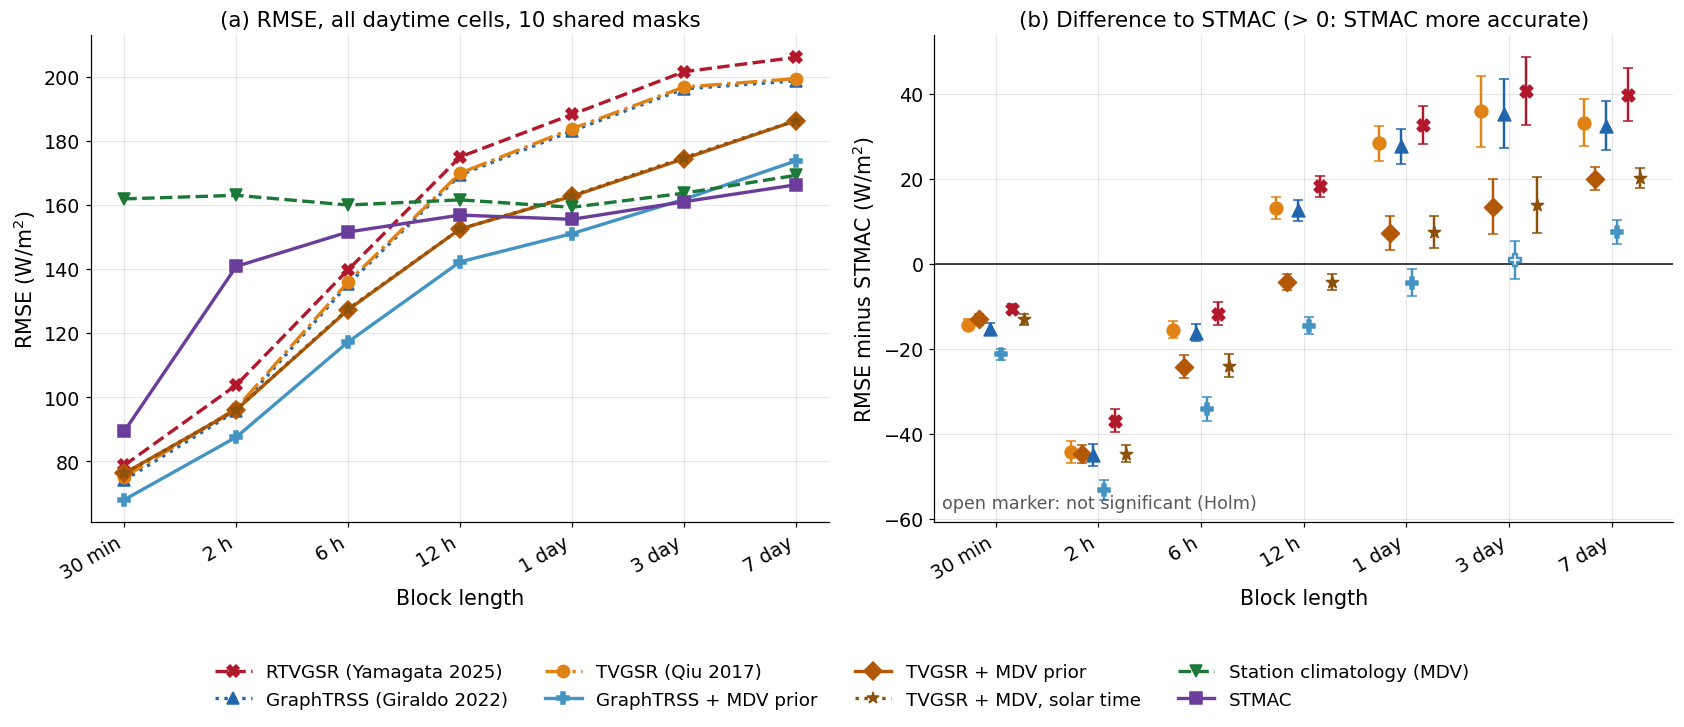

In [10]:
STYLE = {
    "anomaly": dict(c="#6a3d9a", m="s", ls="-", lab="STMAC"),
    "climatology": dict(c="#1b7837", m="v", ls="--", lab="Station climatology (MDV)"),
    "tvgsr": dict(c="#e08214", m="o", ls="-.", lab="TVGSR (Qiu 2017)"),
    "tvgsr_mdv": dict(c="#b35806", m="D", ls="-", lab="TVGSR + MDV prior"),
    "graphtrss": dict(c="#2166ac", m="^", ls=":", lab="GraphTRSS (Giraldo 2022)"),
    "graphtrss_mdv": dict(c="#4393c3", m="P", ls="-", lab="GraphTRSS + MDV prior"),
    "rtvgsr": dict(c="#b2182b", m="X", ls="--", lab="RTVGSR (Yamagata 2025)"),
    "tvgsr_mdv_lst": dict(c="#8c510a", m="*", ls=":", lab="TVGSR + MDV, solar time"),
}
x = np.arange(len(BLOCKS))
labs = [l for _, l in BLOCKS]
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2))
ax = axes[0]
for k in ["rtvgsr", "graphtrss", "tvgsr", "graphtrss_mdv", "tvgsr_mdv", "tvgsr_mdv_lst", "climatology", "anomaly"]:
    s = STYLE[k]
    ax.plot(x, S14["all"].loc[labs, k], marker=s["m"], ls=s["ls"], color=s["c"], lw=2.2, ms=8,
            label=s["lab"], zorder=3 if k == "anomaly" else 2)
ax.set_xticks(x); ax.set_xticklabels(labs, rotation=30, ha="right")
ax.set_xlabel("Block length"); ax.set_ylabel(r"RMSE (W/m$^2$)")
ax.set_title("(a) RMSE, all daytime cells, 10 shared masks")

ax = axes[1]
off = np.linspace(-0.27, 0.27, 6)
for j, k in enumerate(["tvgsr", "tvgsr_mdv", "graphtrss", "graphtrss_mdv", "rtvgsr", "tvgsr_mdv_lst"]):
    s = STYLE[k]
    t = T14[(T14.a == k) & (T14.subset == "all")].set_index("label").loc[labs]
    sig = t.p_holm.values < 0.05
    ax.errorbar(x + off[j], t.mean_diff, yerr=[t.mean_diff - t.ci_lo, t.ci_hi - t.mean_diff],
                fmt="none", ecolor=s["c"], elinewidth=1.6, capsize=3)
    ax.scatter(x[sig] + off[j], t.mean_diff[sig], marker=s["m"], s=70, color=s["c"], label=s["lab"], zorder=3)
    ax.scatter(x[~sig] + off[j], t.mean_diff[~sig], marker=s["m"], s=70, facecolors="white",
               edgecolors=s["c"], linewidths=1.6, zorder=3)
ax.axhline(0, color="0.2", lw=1.2)
ax.set_xticks(x); ax.set_xticklabels(labs, rotation=30, ha="right")
ax.set_xlabel("Block length"); ax.set_ylabel(r"RMSE minus STMAC (W/m$^2$)")
ax.set_title("(b) Difference to STMAC (> 0: STMAC more accurate)")
ax.text(0.01, 0.02, "open marker: not significant (Holm)", transform=ax.transAxes, fontsize=11.5,
        color="0.35", va="bottom")
h0, l0 = axes[0].get_legend_handles_labels()
fig.legend(h0, l0, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(RES / "E14_recent_graph_baselines.png")
plt.show()

Pembacaan otomatis Gambar E14 dari angka yang sama dengan panel (a) dan (b).

In [11]:
print("PEMBACAAN GAMBAR E14")
print("=" * 88)
sa = S14["all"]
for k in ["anomaly", "climatology", "tvgsr", "tvgsr_mdv", "graphtrss", "graphtrss_mdv", "rtvgsr", "tvgsr_mdv_lst"]:
    v = sa.loc[labs, k]
    print(f"- Panel (a), {NAMES[k]}: {idn(v.iloc[0])} W/m2 pada 30 min, {idn(v.loc['6 h'])} pada 6 h, "
          f"{idn(v.iloc[-1])} pada 7 day (pertumbuhan {idn(v.iloc[-1] / v.iloc[0], 2)} kali).")
for k in ["tvgsr", "tvgsr_mdv"]:
    t = T14[(T14.a == k) & (T14.subset == "all")].set_index("label").loc[labs]
    neg = t[(t.mean_diff < 0) & (t.p_holm < 0.05)]
    pos = t[(t.mean_diff > 0) & (t.p_holm < 0.05)]
    print(f"- Panel (b), {NAMES[k]}: di bawah nol (signifikan) pada {', '.join(neg.index) or 'tidak ada blok'}; "
          f"di atas nol (signifikan) pada {', '.join(pos.index) or 'tidak ada blok'}.")

PEMBACAAN GAMBAR E14
- Panel (a), STMAC: 89,4 W/m2 pada 30 min, 151,5 pada 6 h, 166,3 pada 7 day (pertumbuhan 1,86 kali).
- Panel (a), MDV: 161,8 W/m2 pada 30 min, 159,9 pada 6 h, 169,2 pada 7 day (pertumbuhan 1,05 kali).
- Panel (a), TVGSR: 75,0 W/m2 pada 30 min, 136,0 pada 6 h, 199,4 pada 7 day (pertumbuhan 2,66 kali).
- Panel (a), TVGSR + MDV: 76,2 W/m2 pada 30 min, 127,3 pada 6 h, 186,2 pada 7 day (pertumbuhan 2,44 kali).
- Panel (a), GraphTRSS: 74,1 W/m2 pada 30 min, 135,3 pada 6 h, 198,7 pada 7 day (pertumbuhan 2,68 kali).
- Panel (a), GraphTRSS + MDV: 68,0 W/m2 pada 30 min, 117,2 pada 6 h, 173,7 pada 7 day (pertumbuhan 2,55 kali).
- Panel (a), RTVGSR: 78,7 W/m2 pada 30 min, 139,8 pada 6 h, 206,0 pada 7 day (pertumbuhan 2,62 kali).
- Panel (a), TVGSR + MDV, waktu surya: 76,2 W/m2 pada 30 min, 127,5 pada 6 h, 186,3 pada 7 day (pertumbuhan 2,44 kali).
- Panel (b), TVGSR: di bawah nol (signifikan) pada 30 min, 2 h, 6 h; di atas nol (signifikan) pada 12 h, 1 day, 3 day, 7 day.
- Pane

## 6. Waktu komputasi

Waktu dicatat per metode per *mask* pada evaluasi di atas, termasuk perakitan sistem. Waktu STMAC diambil dari pemeriksaan E12 (sekitar satu detik per *mask* pada data setahun).

In [12]:
secs = E14[[c for c in E14.columns if c.startswith("sec_")]].rename(columns=lambda c: NAMES[c[4:]])
TM = secs.agg(["mean", "max"]).T
ru.atomic_csv(TM.reset_index().rename(columns={"index": "metode"}), RES / "E14_runtime.csv")
print(TM.to_string(float_format=lambda v: f"{v:7.2f}"))
print()
print("INTERPRETASI WAKTU KOMPUTASI")
print("=" * 88)
fast = TM["mean"].idxmin(); slow = TM["mean"].idxmax()
print(f"- Metode tercepat {fast} ({idn(TM.loc[fast, 'mean'], 2)} detik per mask), terlambat {slow} "
      f"({idn(TM.loc[slow, 'mean'], 2)} detik). Semua metode berjalan pada CPU tanpa training.")

                            mean     max
TVGSR                       1.53    1.95
TVGSR + MDV                 1.53    1.83
GraphTRSS                   1.53    1.89
GraphTRSS + MDV             1.53    1.89
RTVGSR                     10.49   11.96
TVGSR + MDV, waktu surya    2.84    3.24

INTERPRETASI WAKTU KOMPUTASI
- Metode tercepat TVGSR + MDV (1,53 detik per mask), terlambat RTVGSR (10,49 detik). Semua metode berjalan pada CPU tanpa training.


## 7. Ringkasan temuan

Sel berikut merangkum hasil yang menjawab komentar reviewer dan menyimpannya ke `E14_summary_numbers.csv`. Ringkasan dihasilkan dari angka yang baru dihitung, jadi isinya mengikuti hasil aktual setiap kali notebook dijalankan.

In [13]:
NUM = []
for subset in S14:
    for lab in labs:
        for k in cols:
            NUM.append({"subset": subset, "label": lab, "method": k, "rmse": S14[subset].loc[lab, k]})
for r in T14.itertuples():
    NUM.append({"subset": r.subset, "label": r.label, "method": f"diff_{r.a}_minus_anomaly",
                "rmse": r.mean_diff, "note": f"wins_stmac {r.wins_b}/{r.n}, p_holm {r.p_holm:.2e}"})
ru.atomic_csv(pd.DataFrame(NUM), RES / "E14_summary_numbers.csv")

print("RINGKASAN E14")
print("=" * 88)
avg = sa[cols].mean()
print("1. Rata-rata RMSE atas tujuh panjang blok (W/m2): " +
      "; ".join(f"{NAMES[k]} {idn(avg[k])}" for k in avg.sort_values().index) + ".")
nb_better = {a: verdict(a)[1] for a in GRIDS}
nb_worse = {a: verdict(a)[2] for a in GRIDS}
print("2. Jumlah panjang blok di mana pembanding lebih akurat secara signifikan dari STMAC: " +
      "; ".join(f"{NAMES[a]} {len(nb_better[a])}" for a in GRIDS) + ".")
print("3. Jumlah panjang blok di mana STMAC lebih akurat secara signifikan: " +
      "; ".join(f"{NAMES[a]} {len(nb_worse[a])}" for a in GRIDS) + ".")
short = [l for l in labs[:3]]
long_ = [l for l in labs[3:]]
bs = sa.loc[short, list(GRIDS)].min(axis=1) - sa.loc[short, "anomaly"]
bl_ = sa.loc[long_, list(GRIDS)].min(axis=1) - sa.loc[long_, "anomaly"]
print(f"4. Blok 30 min sampai 6 h: pembanding graf terbaik berselisih {idn(bs.min())} sampai {idn(bs.max())} W/m2 "
      f"terhadap STMAC. Blok 12 h sampai 7 day: {idn(bl_.min())} sampai {idn(bl_.max())} W/m2.")
d_prior = (sa["tvgsr"] - sa["tvgsr_mdv"])
print(f"5. Prior MDV mengubah RMSE TVGSR sebesar {idn(d_prior.min())} sampai {idn(d_prior.max())} W/m2 "
      "(positif berarti prior menurunkan galat).")
d_lst = sa["tvgsr_mdv"] - sa["tvgsr_mdv_lst"]
print(f"6. Pergeseran waktu surya pada TVGSR + MDV mengubah RMSE sebesar {idn(d_lst.min())} sampai "
      f"{idn(d_lst.max())} W/m2 (positif berarti pergeseran menurunkan galat).")
print(f"7. Konfigurasi terpilih: " + "; ".join(f"{NAMES[k]} {best.loc[k, 'cfg']}" for k in GRIDS) + ".")

RINGKASAN E14
1. Rata-rata RMSE atas tujuh panjang blok (W/m2): GraphTRSS + MDV 128,8; TVGSR + MDV 139,3; TVGSR + MDV, waktu surya 139,4; STMAC 145,9; GraphTRSS 150,3; TVGSR 151,0; RTVGSR 156,1; MDV 162,6.
2. Jumlah panjang blok di mana pembanding lebih akurat secara signifikan dari STMAC: TVGSR 3; TVGSR + MDV 4; GraphTRSS 3; GraphTRSS + MDV 5; RTVGSR 3; TVGSR + MDV, waktu surya 4.
3. Jumlah panjang blok di mana STMAC lebih akurat secara signifikan: TVGSR 4; TVGSR + MDV 3; GraphTRSS 4; GraphTRSS + MDV 1; RTVGSR 4; TVGSR + MDV, waktu surya 3.
4. Blok 30 min sampai 6 h: pembanding graf terbaik berselisih -53,3 sampai -21,4 W/m2 terhadap STMAC. Blok 12 h sampai 7 day: -14,6 sampai 7,4 W/m2.
5. Prior MDV mengubah RMSE TVGSR sebesar -1,2 sampai 22,4 W/m2 (positif berarti prior menurunkan galat).
6. Pergeseran waktu surya pada TVGSR + MDV mengubah RMSE sebesar -0,3 sampai 0,0 W/m2 (positif berarti pergeseran menurunkan galat).
7. Konfigurasi terpilih: TVGSR {"nu": 10.0}; TVGSR + MDV {"nu": 1